# Qwen 3.8 × ARC: LT用の図

凍結済みの集計スナップショットから、スライド用SVGを再生成します。モデル実行、ネットワーク、正解ファイルや非公開データは不要です。候補2件は記録された試行であり、独立サンプルとは限りません。

## 出典と条件

- 単体：`15_qwen38_phase_a_results.ipynb`。Qwen3.8-27B FP8、A100、公開Training 200問、2候補。175は2候補とも正解しなかったタスクで、形式不正も含む。
- 誤答例：公開Training `25d8a9c8`、同200問のFP8の第1候補。提示済みの4例の入力・出力とテスト入力、保存済み候補のみ収録。テストの正解は収録しない。既に調査済みの50問に含まれ、予約済み25問には含まれない。
- 比較：[PR #17](https://github.com/morshoto/qwen-meetup-2/blob/issue/16-qwen38-weight-optimization/docs/qwen38-weight-optimization-results.md) と [PR #19](https://github.com/morshoto/qwen-meetup-2/blob/issue/18-frozen-lora-replication/docs/qwen38-replication-results.md)。ローカルMLX 4-bit、同一adapter、探索的な50問と別の25問。
- [Kaggle ARC Prize 2026 - ARC-AGI-2 公開リーダーボード](https://www.kaggle.com/competitions/arc-prize-2026-arc-agi-2/leaderboard)：2026-11-10 14:45 UTC取得、順位1〜3543のチームごとの表示スコアを算術平均。順位0の1行を除外。合計76370.52百分率ポイント／3543＝21.5553%。CSV SHA-256 `79afa70de5ae7f882a06005e2c6dd098e6222c6c0e02411e55b16362d4e9e02d`。暫定金17位75.14%、銀177位33.47%、銅354位32.22%。[順位表の記録](https://arc.markbarney.net/news)のメダル圏と照合。境界には同点チームがあり、表示スコアだけで受賞を保証できない。最終Private順位は未公開。公開コンペ評価であり、今回のTraining問題の正解率と直接比較不可。

誤答例の集計記録 SHA-256：`f07534b2a20704cda4eb19879b43d047bfb34d865e94e24028be552ace58f77e`。第1候補は単一グリッドのラップによる形式回復後の出力。

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import numpy as np

repo = Path.cwd().resolve()
while not (repo / 'presentation' / 'slide.md').is_file():
    if repo == repo.parent:
        raise FileNotFoundError('Run from the repository root or a directory inside it')
    repo = repo.parent
out = repo / 'presentation' / 'img'
out.mkdir(parents=True, exist_ok=True)
font_names = {f.name for f in font_manager.fontManager.ttflist}
font = next((f for f in ['Hiragino Sans', 'Noto Sans CJK JP', 'Noto Sans JP', 'IPAexGothic'] if f in font_names), None)
if font is None: raise RuntimeError('Japanese font required: install Noto Sans CJK JP or use macOS Hiragino Sans')
plt.rcParams.update({'font.family':font, 'svg.fonttype':'none', 'font.size':16, 'axes.spines.top':False, 'axes.spines.right':False, 'figure.facecolor':'white', 'savefig.facecolor':'white'})
NAVY='#172f4e'; BLUE='#2b78bd'; TEAL='#128d8e'; MUTED='#596a80'; LIGHT='#dce8f2'; AMBER='#bc7928'
def save(fig, name):
    fig.savefig(out / name, format='svg', bbox_inches='tight', pad_inches=.10)
    plt.show()
    plt.close(fig)
print('Japanese font:', font, '| output:', out)

Japanese font: Hiragino Sans | output: /Users/shotomorisaki/Engineering/qwen-meetup-2/presentation/img


## 実験の方法

図は実施済みの重み更新と評価を示す。検証方法や適格性を同一視しない。

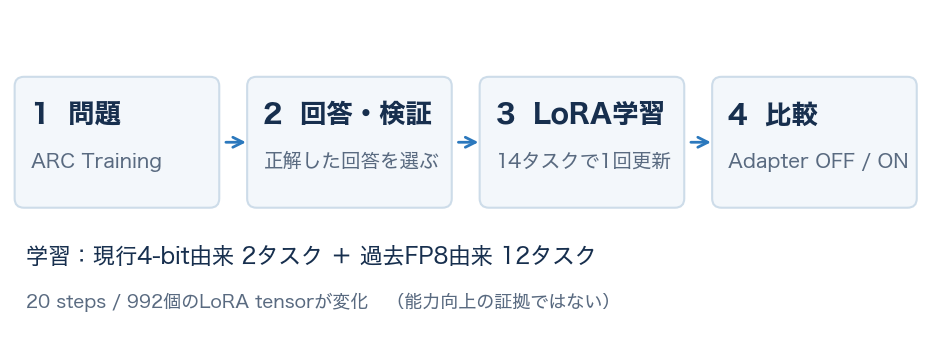

In [2]:
fig, ax = plt.subplots(figsize=(12,4.35)); ax.set_xlim(0,12); ax.set_ylim(0,4.35); ax.axis('off')
steps=[('1  問題','ARC Training'),('2  回答・検証','正解した回答を選ぶ'),('3  LoRA学習','14タスクで1回更新'),('4  比較','Adapter OFF / ON')]
for i,(title, sub) in enumerate(steps):
    x=.12+i*3.0
    ax.add_patch(FancyBboxPatch((x,1.83),2.52,1.58,boxstyle='round,pad=0.06,rounding_size=0.12',facecolor='#f3f7fb',edgecolor='#cddce9',linewidth=1.5))
    ax.text(x+.15,2.88,title,fontsize=19,fontweight='bold',color=NAVY)
    ax.text(x+.15,2.30,sub,fontsize=14,color=MUTED)
    if i<3: ax.add_patch(FancyArrowPatch((x+2.63,2.62),(x+2.96,2.62),arrowstyle='->',mutation_scale=18,linewidth=2,color=BLUE))
ax.text(.2,1.05,'学習：現行4-bit由来 2タスク ＋ 過去FP8由来 12タスク',fontsize=16,color=NAVY)
ax.text(.2,.48,'20 steps / 992個のLoRA tensorが変化　（能力向上の証拠ではない）',fontsize=13,color=MUTED)
save(fig,'lt-method.svg')

## Qwen 3.8単体と誤答例

公開Training問題 `25d8a9c8` の提示済み例4組、テスト入力と保存済み第1候補を表示する。テスト正解は収録・表示しない。候補は形式回復後であり、記録に基づいて不正解と確認済み。

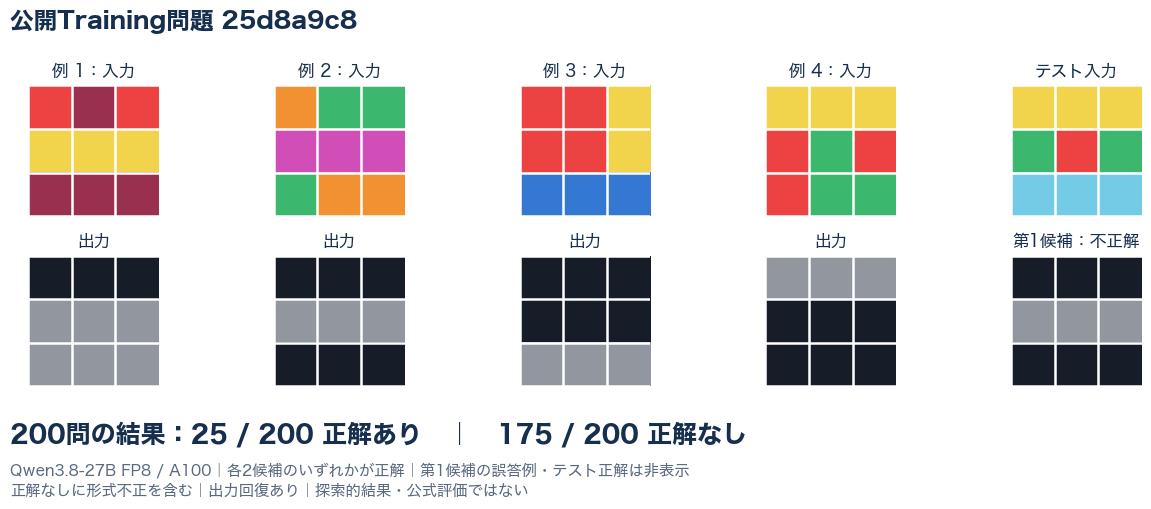

In [3]:
examples=[
 ([[2,9,2],[4,4,4],[9,9,9]], [[0,0,0],[5,5,5],[5,5,5]]),
 ([[7,3,3],[6,6,6],[3,7,7]], [[0,0,0],[5,5,5],[0,0,0]]),
 ([[2,2,4],[2,2,4],[1,1,1]], [[0,0,0],[0,0,0],[5,5,5]]),
 ([[4,4,4],[2,3,2],[2,3,3]], [[5,5,5],[0,0,0],[0,0,0]]),
]
test_input=[[4,4,4],[3,2,3],[8,8,8]]
prediction=[[0,0,0],[5,5,5],[0,0,0]]
colors=['#171d28','#3478d4','#ed4242','#3bb86e','#f1d34c','#92979f','#d14db8','#f19132','#74cbe5','#9a3050']
cmap=ListedColormap(colors); norm=BoundaryNorm(np.arange(-.5,10,.999),cmap.N)
fig,axes=plt.subplots(2,5,figsize=(12.5,5.1));fig.subplots_adjust(left=.03,right=.97,bottom=.24,top=.83,wspace=.28,hspace=.30)
def grid(ax, values, label):
    a=np.array(values); ax.imshow(a,cmap=cmap,norm=norm,interpolation='nearest'); ax.set_xticks(np.arange(-.5,a.shape[1],1),minor=True);ax.set_yticks(np.arange(-.5,a.shape[0],1),minor=True);ax.grid(which='minor',color='white',linewidth=1.8);ax.tick_params(which='both',bottom=False,left=False,labelbottom=False,labelleft=False);[x.set_visible(False) for x in ax.spines.values()];ax.set_title(label,fontsize=12,color=NAVY,pad=6)
for i,(inp,outp) in enumerate(examples):
    grid(axes[0,i],inp,f'例 {i+1}：入力');grid(axes[1,i],outp,'出力')
grid(axes[0,4],test_input,'テスト入力');grid(axes[1,4],prediction,'第1候補：不正解')
fig.text(.04,.94,'公開Training問題 25d8a9c8',fontsize=17,fontweight='bold',color=NAVY)
fig.text(.04,.13,'200問の結果：25 / 200 正解あり　｜　175 / 200 正解なし',fontsize=18,fontweight='bold',color=NAVY)
fig.text(.04,.065,'Qwen3.8-27B FP8 / A100｜各2候補のいずれかが正解｜第1候補の誤答例・テスト正解は非表示',fontsize=11,color=MUTED)
fig.text(.04,.025,'正解なしに形式不正を含む｜出力回復あり｜探索的結果・公式評価ではない',fontsize=11,color=MUTED)
save(fig,'lt-qwen38-baseline.svg')

## 正解数の比較

OFF/ONは同じ問題内の比較。Kaggle平均・暫定メダル圏は2026年の公開順位表。評価問題・システムが異なり直接比較はできない。

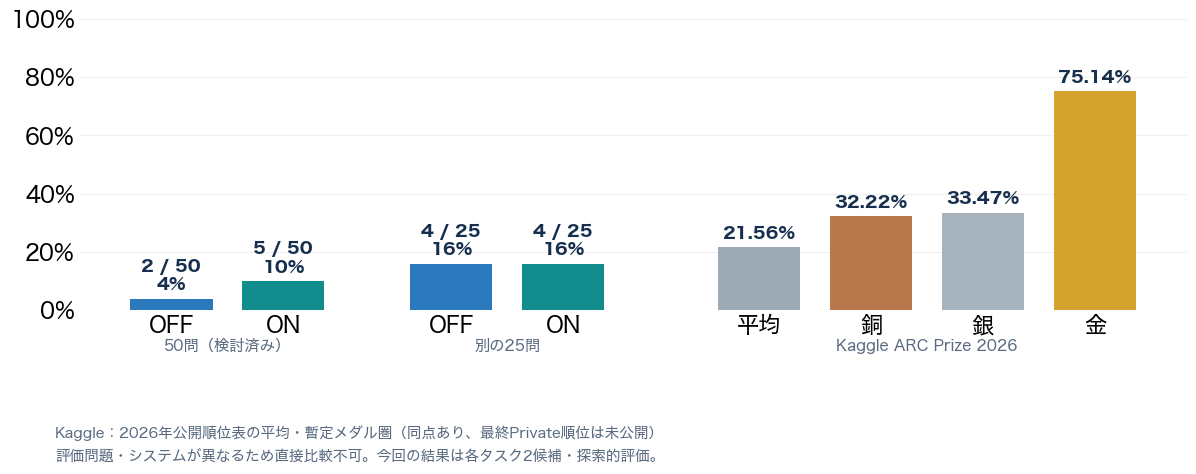

In [4]:
fig,ax=plt.subplots(figsize=(12.3,5.2));fig.subplots_adjust(left=.08,right=.98,bottom=.32,top=.88)
xs=[0,.8,2,2.8,4.2,5.0,5.8,6.6]
vals=[4,10,16,16,76370.52/3543,32.22,33.47,75.14]
labels=['2 / 50\n4%','5 / 50\n10%','4 / 25\n16%','4 / 25\n16%','21.56%','32.22%','33.47%','75.14%']
colors=[BLUE,TEAL,BLUE,TEAL,'#9daab6','#b8784b','#a7b3bd','#d4a32d']
ax.bar(xs,vals,width=.59,color=colors,edgecolor='none')
for x,v,label in zip(xs,vals,labels): ax.text(x,v+1.6,label,ha='center',va='bottom',fontsize=12.5,fontweight='bold',color=NAVY,linespacing=1.08)
ax.set_xticks(xs,['OFF','ON','OFF','ON','平均','銅','銀','金']);ax.set_ylim(0,100);ax.set_yticks([0,20,40,60,80,100],[f'{v}%' for v in [0,20,40,60,80,100]]);ax.grid(axis='y',alpha=.18);ax.set_axisbelow(True);ax.spines[['left','bottom']].set_visible(False);ax.tick_params(length=0)
ax.text(.4,-.14,'50問（検討済み）',transform=ax.get_xaxis_transform(),ha='center',fontsize=11,color=MUTED)
ax.text(2.4,-.14,'別の25問',transform=ax.get_xaxis_transform(),ha='center',fontsize=11,color=MUTED)
ax.text(5.4,-.14,'Kaggle ARC Prize 2026',transform=ax.get_xaxis_transform(),ha='center',fontsize=11,color=MUTED)
fig.text(.06,.075,'Kaggle：2026年公開順位表の平均・暫定メダル圏（同点あり、最終Private順位は未公開）',fontsize=10.5,color=MUTED)
fig.text(.06,.03,'評価問題・システムが異なるため直接比較不可。今回の結果は各タスク2候補・探索的評価。',fontsize=10.5,color=MUTED)
save(fig,'lt-correctness.svg')

## 出力形式の比較

正解ではなく、パーサーがグリッド候補として読み取れた割合。

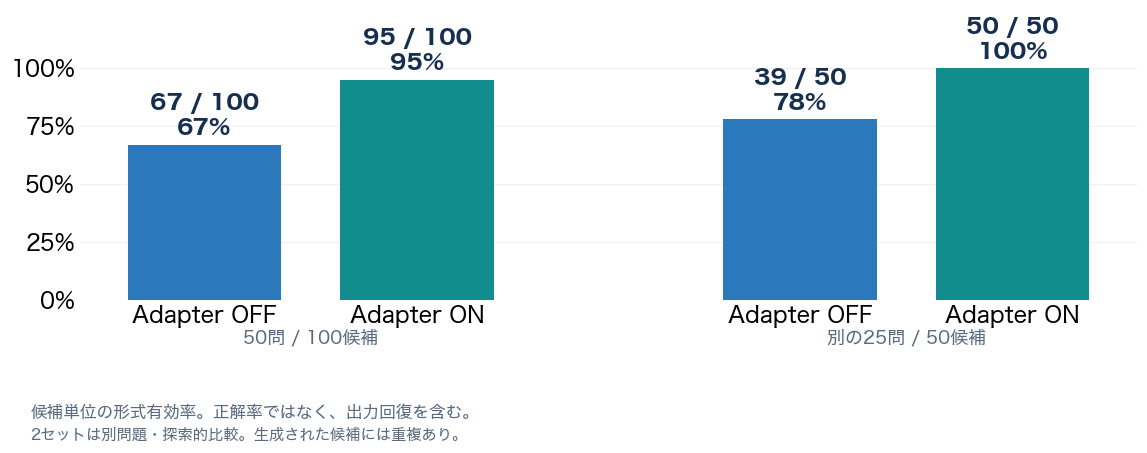

In [5]:
fig,ax=plt.subplots(figsize=(12.3,5.0));fig.subplots_adjust(left=.10,right=.96,bottom=.30,top=.88)
xs=[0,1,2.8,3.8];values=[67,95,78,100];counts=['67 / 100','95 / 100','39 / 50','50 / 50'];colors=[BLUE,TEAL,BLUE,TEAL]
ax.bar(xs,values,width=.72,color=colors)
for x,v,n in zip(xs,values,counts):ax.text(x,v+2,f'{n}\n{v}%',ha='center',va='bottom',fontsize=16,fontweight='bold',color=NAVY,linespacing=1.15)
ax.set_xticks(xs,['Adapter OFF','Adapter ON','Adapter OFF','Adapter ON']);ax.set_ylim(0,125);ax.set_yticks([0,25,50,75,100],[f'{v}%' for v in [0,25,50,75,100]]);ax.grid(axis='y',alpha=.18);ax.set_axisbelow(True);ax.spines[['left','bottom']].set_visible(False);ax.tick_params(length=0)
ax.text(.5,-.15,'50問 / 100候補',transform=ax.get_xaxis_transform(),ha='center',fontsize=13,color=MUTED)
ax.text(3.3,-.15,'別の25問 / 50候補',transform=ax.get_xaxis_transform(),ha='center',fontsize=13,color=MUTED)
fig.text(.06,.065,'候補単位の形式有効率。正解率ではなく、出力回復を含む。',fontsize=12,color=MUTED)
fig.text(.06,.02,'2セットは別問題・探索的比較。生成された候補には重複あり。',fontsize=11,color=MUTED)
save(fig,'lt-format-validity.svg')